# Check for data before training

In [2]:
import os 
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.append(str(ROOT / "src"))

import cv2
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

from dataset import pad_to_square, get_transforms

df = pd.read_csv("data/manifest.csv")
print(f"{len(df)} images")
df.head()

78 images


,species,sclere_type,image_number,image_path
0,A. argyrosperma,gemmulosclere,1,C:\Users\st-lab105\Desktop\freshwater_sponge_m...
1,A. argyrosperma,gemmulosclere,2,C:\Users\st-lab105\Desktop\freshwater_sponge_m...
2,A. argyrosperma,gemmulosclere,3,C:\Users\st-lab105\Desktop\freshwater_sponge_m...
3,A. argyrosperma,gemmulosclere,4,C:\Users\st-lab105\Desktop\freshwater_sponge_m...
4,A. argyrosperma,gemmulosclere,5,C:\Users\st-lab105\Desktop\freshwater_sponge_m...


# How many images exist per specie

species
D. radiospiculata                    13
A. argyrosperma                      11
C. becki                              9
S. alba                               8
T. horrida                            8
E. fragilis                           7
E. muelleri                           6
R. cerebellata                        5
S. lacustrus                          5
T. Leidyi                             4
freshwater_sponge_model_origianal     1
R.crateriformis                       1
Name: count, dtype: int64


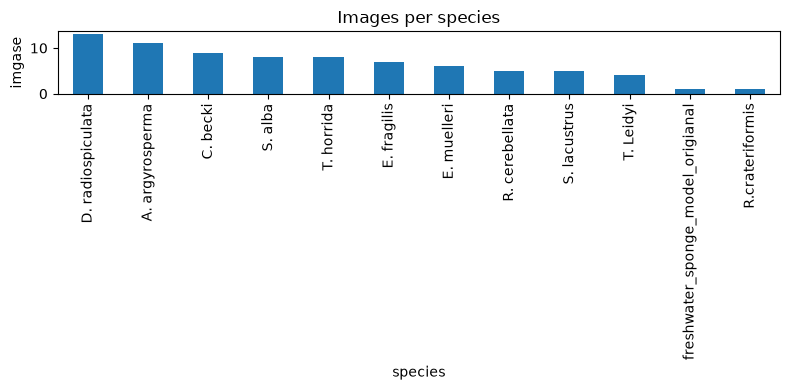


sclere_type                        gemmulosclere  megasclere  microsclere
species                                                                  
A. argyrosperma                                9           2            0
C. becki                                       1           3            5
D. radiospiculata                              9           1            3
E. fragilis                                    5           2            0
E. muelleri                                    3           3            0
R. cerebellata                                 5           0            0
R.crateriformis                                1           0            0
S. alba                                        3           2            3
S. lacustrus                                   1           2            2
T. Leidyi                                      2           2            0
T. horrida                                     3           5            0
freshwater_sponge_model_origianal    

In [3]:
counts = df["species"].value_counts()
print(counts)

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.bar(ax=ax)
ax.set_ylabel("imgase")
ax.set_title("Images per species")
plt.tight_layout()
plt.show()

if "specimen-id" in df.columns:
    print()
    print(df.groupby("species")["specimen_id"].numerique().rename("specimen"))
if "sclere_type" in df.columns:
    print()
    print(pd.crosstab(df["species"], df["sclere_type"]))

#  Visialize the images (Original VS Padded Images)

In [7]:
def load_rgb(path):
    img = cv2.imread(path)
    if img is None:
        raise FileExistsError(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def thumb(img, max_side=500):
    """Shrink the images if needed for display only, so huge microscope images do not slow the notebook. """
    scale = max_side / max(img.shape[:2])
    if scale >= 1:
        return img
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

def show_grid(images, titles, cols=4, size=3):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.suplots(rows, cols, figsize=(cols * size, rows * size))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im)
        ax.set_title(t, fontsize=8)
    plt.tight_layout 
    plt.show()

sample = df.sample(min(8, len(df)), random_state=0)
originals, padded, titles = [], [], []
for _, row in sample.iterrows():
    img = load_rgb(row["image_path"])
    originals.append(thumb(img))
    padded.append(cv2.resize(pad_to_square(img), (224,224)))
    titles.append(row["species"])

print("Original images:")
show_grid(originals, titles)
print("After padding to a square and resizing to 224 X 224 (what the model sees):")
show_grid(padded, titles)

Original images:


AttributeError: module 'matplotlib.pyplot' has no attribute 'suplots'